# Predictive Model Development and Algorithm Comparison Using Python

**Dataset:** Wisconsin Breast Cancer Diagnostic Dataset (built into scikit-learn)  
**Task:** Binary classification — malignant vs. benign  
**Algorithms:** Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest

## Learning objectives
1. Load and inspect a real-world dataset.
2. Explore class balance, distributions, missing values and feature relationships.
3. Split the data using stratified sampling.
4. Train five classification algorithms using leakage-safe pipelines.
5. Compare accuracy, precision, recall, F1-score, ROC-AUC and training time.
6. Inspect confusion matrices and ROC curves.
7. Evaluate malignant-case detection separately.
8. Use cross-validation to assess stability.

> **Important:** This is an educational experiment, not a clinical diagnostic tool. Model performance on this dataset does not establish clinical validity or suitability for patient care.


## 1. Install dependencies 

In [ ]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

## 2. Import libraries and load the dataset

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy()

# In scikit-learn: 0 = malignant, 1 = benign
class_names = ["malignant", "benign"]

print("Dataset:", dataset.DESCR.splitlines()[0])
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass counts:")
print(y.map({0: "malignant", 1: "benign"}).value_counts())
print("\nFirst five observations:")
display(X.head())


Dataset: .. _breast_cancer_dataset:
Feature matrix shape: (569, 30)
Target shape: (569,)

Class counts:
target
benign       357
malignant    212
Name: count, dtype: int64

First five observations:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Data inspection and exploratory data analysis

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

None


Missing values per feature (non-zero only):


Series([], dtype: int64)


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


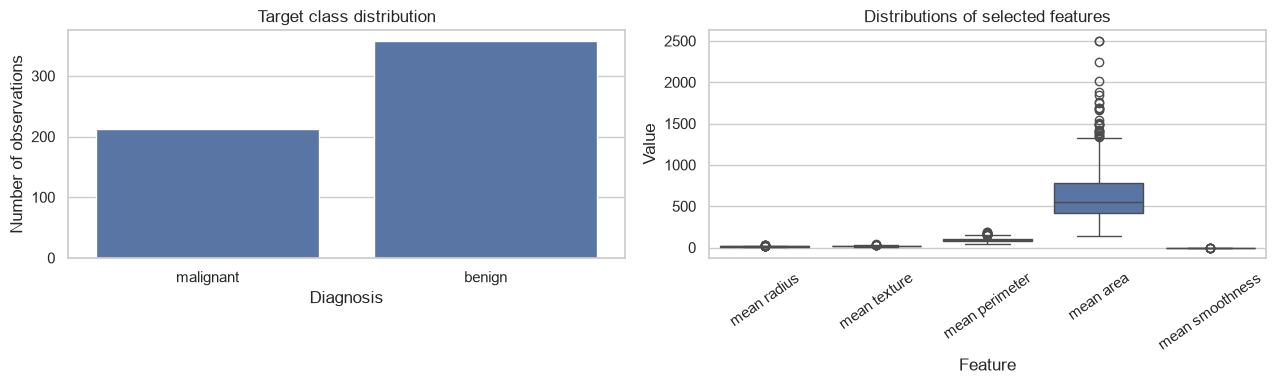

In [2]:
print("Data types and non-null counts:")
display(X.info())

print("\nMissing values per feature (non-zero only):")
missing = X.isna().sum()
display(missing[missing > 0])

print("\nDescriptive statistics:")
display(X.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    x=y.map({0: "malignant", 1: "benign"}),
    order=["malignant", "benign"],
    ax=axes[0]
)
axes[0].set_title("Target class distribution")
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Number of observations")

# Show distributions for a small, interpretable feature subset
selected_features = [
    "mean radius", "mean texture", "mean perimeter",
    "mean area", "mean smoothness"
]
plot_data = X[selected_features].melt(
    var_name="Feature", value_name="Value"
)
sns.boxplot(data=plot_data, x="Feature", y="Value", ax=axes[1])
axes[1].set_title("Distributions of selected features")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


### Feature correlation
The full correlation matrix can be large. This heatmap shows the 12 features with the greatest absolute correlation with `mean radius` (excluding itself). Correlation does not imply causation.

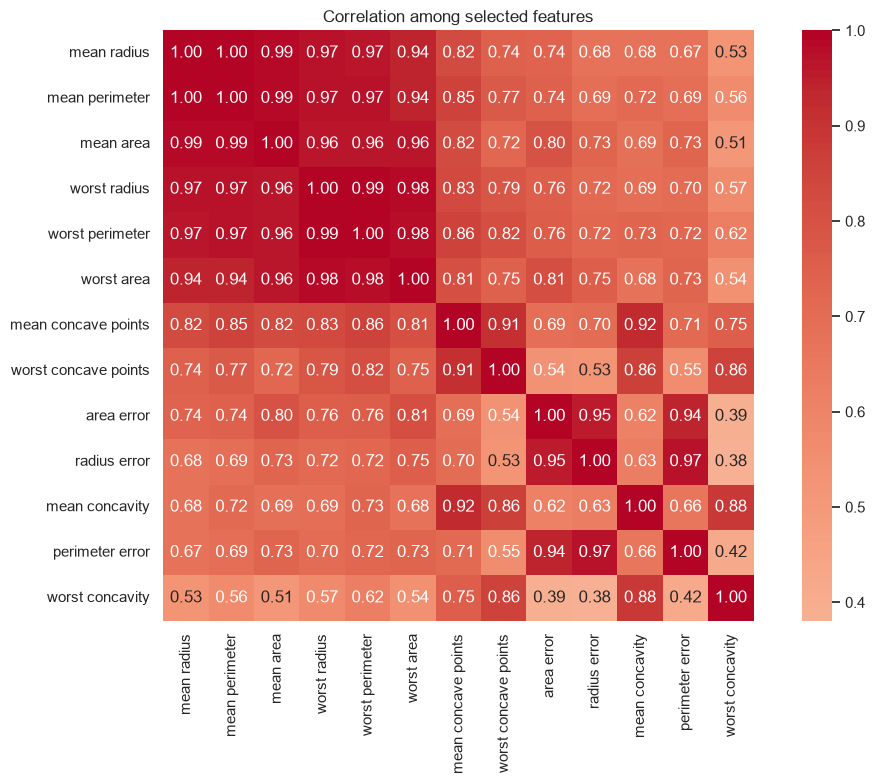

In [3]:
corr = X.corr(numeric_only=True)
top_features = (
    corr["mean radius"]
    .drop("mean radius")
    .abs()
    .sort_values(ascending=False)
    .head(12)
    .index
    .tolist()
)
heatmap_features = ["mean radius"] + top_features

plt.figure(figsize=(11, 8))
sns.heatmap(
    X[heatmap_features].corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)
plt.title("Correlation among selected features")
plt.tight_layout()
plt.show()


## 4. Train-test split
We reserve 20% of the observations for the final test set. `stratify=y` preserves approximately the same class proportions in both partitions.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training observations: {len(X_train)}")
print(f"Test observations:     {len(X_test)}")
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename(index={0: "malignant", 1: "benign"}))
print("\nTest class proportions:")
display(y_test.value_counts(normalize=True).rename(index={0: "malignant", 1: "benign"}))


Training observations: 455
Test observations:     114

Training class proportions:


target
benign       0.626374
malignant    0.373626
Name: proportion, dtype: float64


Test class proportions:


target
benign       0.631579
malignant    0.368421
Name: proportion, dtype: float64

## 5. Define five predictive models

Scaling is included for Logistic Regression, KNN and SVM because they are sensitive to feature scale. Tree-based models do not require standardization. An imputer is included in each pipeline so preprocessing is learned from training data only; this also makes the workflow robust if missing values are introduced in a future dataset.

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

print("Models to evaluate:")
for model_name in models:
    print("-", model_name)


Models to evaluate:
- Logistic Regression
- KNN
- SVM (RBF)
- Decision Tree
- Random Forest


## 6. Train and evaluate the models
The positive label for the standard metrics below is **benign (1)**, following the dataset's target encoding. We separately report malignant-class metrics in Section 9.

In [6]:
results = []
trained_models = {}
test_predictions = {}
test_probabilities = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    y_pred = model.predict(X_test)
    y_prob_benign = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob_benign

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (benign)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall (benign)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score (benign)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC (benign)": roc_auc_score(y_test, y_prob_benign),
        "Training time (s)": elapsed
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC (benign)", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


/Users/rutvik/Phd/env/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Algorithm,Accuracy,Precision (benign),Recall (benign),F1-score (benign),ROC-AUC (benign),Training time (s)
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954,0.0140
1,SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950,0.0096
2,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9931,0.1076
3,KNN,0.9561,0.9589,0.9722,0.9655,0.9788,0.0017
4,Decision Tree,0.9123,0.9559,0.9028,0.9286,0.9157,0.0068


## 7. Visual comparison of evaluation metrics

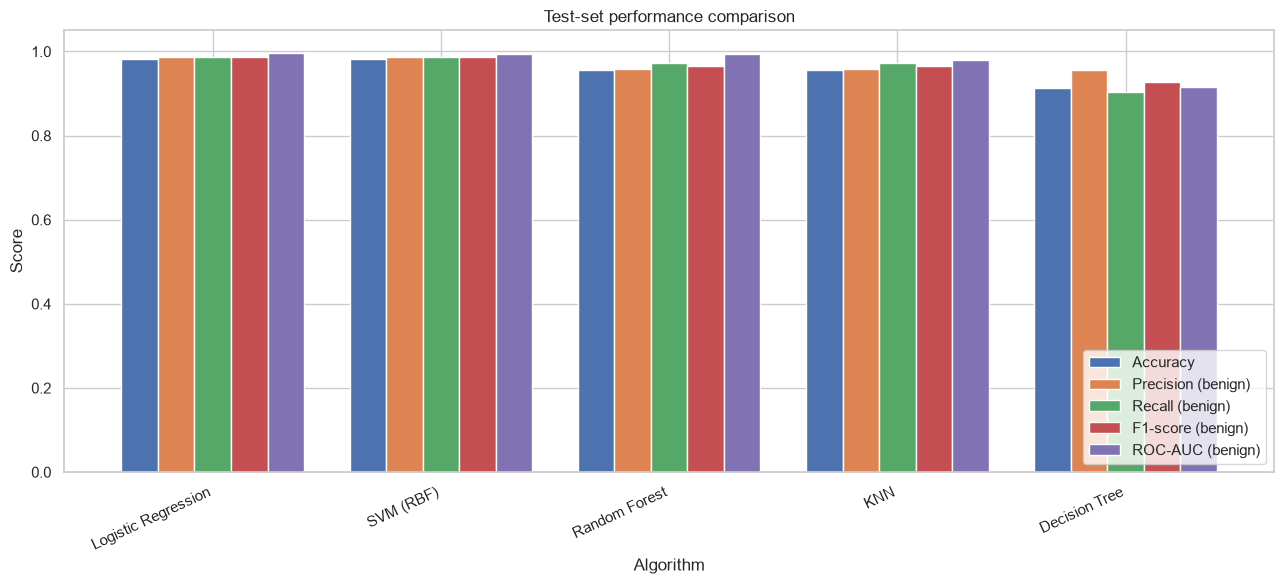

In [7]:
metric_columns = [
    "Accuracy", "Precision (benign)", "Recall (benign)",
    "F1-score (benign)", "ROC-AUC (benign)"
]

ax = (
    results_df.set_index("Algorithm")[metric_columns]
    .plot(kind="bar", figsize=(13, 6), ylim=(0, 1.05), width=0.8)
)
ax.set_title("Test-set performance comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Algorithm")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 8. Confusion matrices
Rows represent actual classes and columns represent predicted classes. Class order is malignant, then benign.

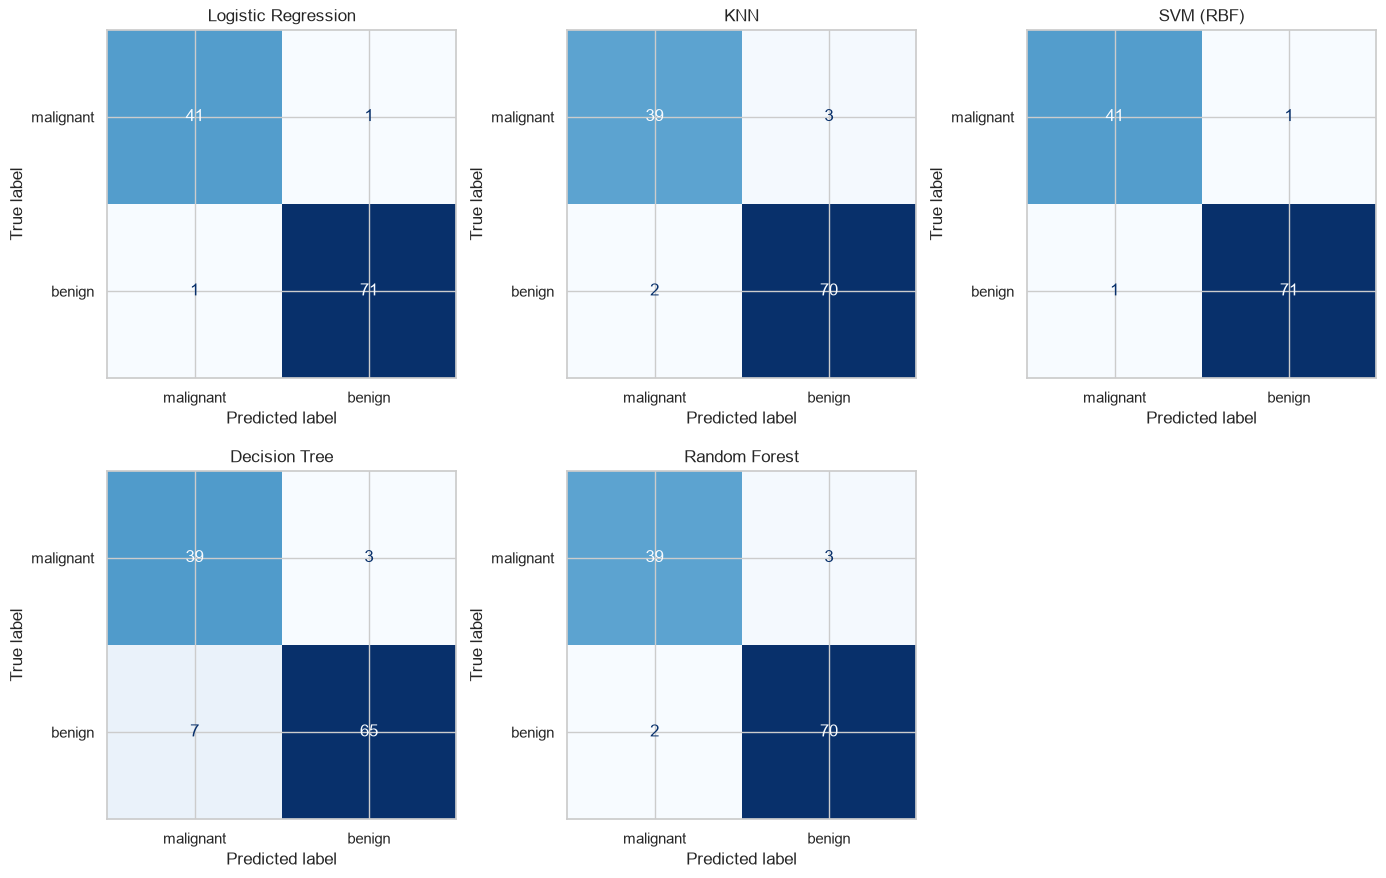

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions[name],
        labels=[0, 1],
        display_labels=class_names,
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

axes[-1].axis("off")
plt.tight_layout()
plt.show()


## 9. Malignant-case detection
For this dataset, malignant is class `0`. In this section, malignant recall answers: **Of all malignant cases in the test set, what proportion did the model identify as malignant?** This is an important metric to inspect, but it should not be interpreted as clinical validation.

In [9]:
malignant_results = []

for name, y_pred in test_predictions.items():
    malignant_results.append({
        "Algorithm": name,
        "Malignant precision": precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Malignant recall (sensitivity)": recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Malignant F1-score": f1_score(y_test, y_pred, pos_label=0, zero_division=0)
    })

malignant_df = pd.DataFrame(malignant_results).sort_values(
    "Malignant recall (sensitivity)", ascending=False
)
display(malignant_df.round(4))


,Algorithm,Malignant precision,Malignant recall (sensitivity),Malignant F1-score
0,Logistic Regression,0.9762,0.9762,0.9762
2,SVM (RBF),0.9762,0.9762,0.9762
1,KNN,0.9512,0.9286,0.9398
3,Decision Tree,0.8478,0.9286,0.8864
4,Random Forest,0.9512,0.9286,0.9398


## 10. ROC curve comparison
The probability score is for class `1` (benign). The ROC-AUC is mathematically equivalent if the positive class is consistently reversed, but the plotted class interpretation changes.

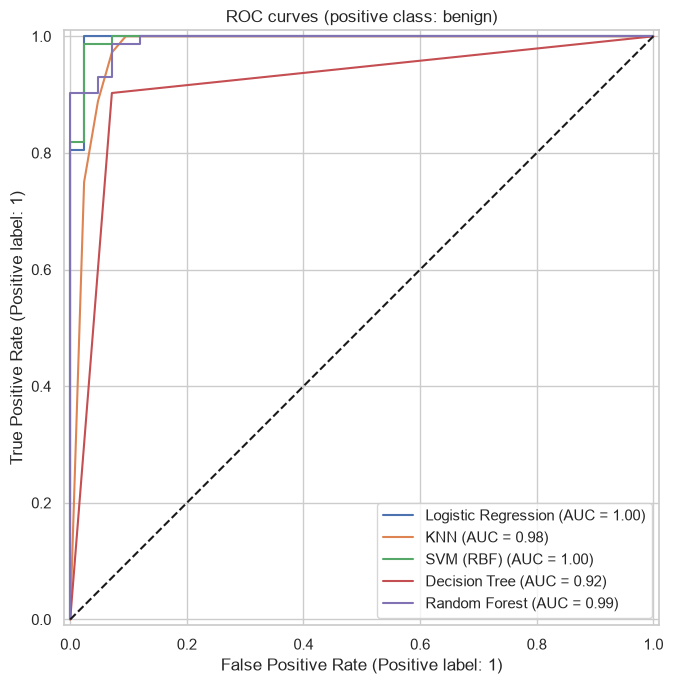

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        pos_label=1,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curves (positive class: benign)")
ax.grid(True)
plt.tight_layout()
plt.show()


## 11. Five-fold stratified cross-validation
Cross-validation is performed on the training data only. This avoids using the held-out test set for model selection. The final test set remains reserved for the one-time comparison above.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "Algorithm": name,
        "CV accuracy mean": scores["test_accuracy"].mean(),
        "CV accuracy std": scores["test_accuracy"].std(),
        "CV F1 mean": scores["test_f1"].mean(),
        "CV ROC-AUC mean": scores["test_roc_auc"].mean(),
        "CV ROC-AUC std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_rows).sort_values(
    "CV ROC-AUC mean", ascending=False
).reset_index(drop=True)

display(cv_df.round(4))


/Users/rutvik/Phd/env/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/rutvik/Phd/env/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/rutvik/Phd/env/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/rutvik/Phd/env/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will 

,Algorithm,CV accuracy mean,CV accuracy std,CV F1 mean,CV ROC-AUC mean,CV ROC-AUC std
0,Logistic Regression,0.9780,0.0098,0.9825,0.9959,0.0050
1,SVM (RBF),0.9692,0.0146,0.9756,0.9956,0.0048
2,Random Forest,0.9626,0.0179,0.9700,0.9895,0.0086
3,KNN,0.9626,0.0112,0.9705,0.9882,0.0081
4,Decision Tree,0.9165,0.0179,0.9319,0.9179,0.0201


## 12. Detailed classification reports

In [12]:
for name, y_pred in test_predictions.items():
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    ))



Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


KNN
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


SVM (RBF)
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98    

## 13. Select a model and save results
For this example, the ranking criterion is test ROC-AUC. In a real research workflow, choose the primary metric before evaluating the test set, based on the problem's costs and objectives. Do not repeatedly tune against the test set.

In [13]:
best_row = results_df.iloc[0]
best_name = best_row["Algorithm"]
best_model = trained_models[best_name]

print("Top model by test ROC-AUC:", best_name)
print("Test ROC-AUC:", round(best_row["ROC-AUC (benign)"], 4))
print("Test accuracy:", round(best_row["Accuracy"], 4))

# Save tables for reporting
results_df.to_csv("model_comparison_test_results.csv", index=False)
malignant_df.to_csv("malignant_detection_metrics.csv", index=False)
cv_df.to_csv("cross_validation_results.csv", index=False)

print("\nSaved:")
print("- model_comparison_test_results.csv")
print("- malignant_detection_metrics.csv")
print("- cross_validation_results.csv")


Top model by test ROC-AUC: Logistic Regression
Test ROC-AUC: 0.9954
Test accuracy: 0.9825

Saved:
- model_comparison_test_results.csv
- malignant_detection_metrics.csv
- cross_validation_results.csv


## 14. Interpretation and discussion template

Complete this section after running the notebook. Use the actual values printed by your run.

### Results
- The highest test ROC-AUC was achieved by **[algorithm]**, with a score of **[value]**.
- The highest test accuracy was achieved by **[algorithm]**, with a score of **[value]**.
- The highest malignant recall was achieved by **[algorithm]**, with a score of **[value]**.
- Cross-validation suggests **[algorithm]** had the most consistent performance based on the mean and standard deviation of the selected metric.

### Discussion points
1. Did scaling improve the performance of distance- or margin-based algorithms?
2. Did the ensemble model outperform the single decision tree?
3. Which model best balanced malignant sensitivity and precision?
4. Were test-set and cross-validation results similar?
5. What are the limitations of the dataset size, feature representation and single-dataset evaluation?

### Limitations
- The dataset contains 569 observations and is not a substitute for large, diverse clinical datasets.
- A random train-test split does not test generalization across hospitals, devices or populations.
- Hyperparameters are baseline choices, not necessarily optimal.
- No external validation or prospective clinical evaluation is performed.
- A high score does not mean the model is safe for diagnosis or treatment decisions.

### Conclusion
This experiment compares five supervised classification algorithms using a consistent preprocessing and evaluation workflow. The preferred model should be selected using the task's pre-defined evaluation priorities, with particular attention to malignant-case recall, precision, ROC-AUC and cross-validation stability. The findings are educational and require external validation before any clinical application.
